In [1]:
import os
import cv2
import torch
import random
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import timm

In [2]:
# 1. Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
# 2. Verified Data Path
data_dir = '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake'

In [4]:
# 3. Corrected Compression Function (BGR -> JPEG -> RGB)
def apply_compression(img_bgr, quality=30):
    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    _, encimg = cv2.imencode('.jpg', img_bgr, encode_param)
    decimg_bgr = cv2.imdecode(encimg, 1)
    # We convert to RGB here because PIL and PyTorch expect RGB
    compressed_rgb = cv2.cvtColor(decimg_bgr, cv2.COLOR_BGR2RGB)
    return compressed_rgb

In [5]:
# Create the custom dataset class
class DeepfakeDataset(Dataset):
    def __init__(self, data_dir, split='train', transform=None, compression_prob=0.5, sample_limit=None):
        self.transform = transform
        self.compression_prob = compression_prob
        self.image_paths = []
        self.labels = []
        
        split_dir = os.path.join(data_dir, split)
        classes = {'real': 0, 'fake': 1}
        
        for cls_name, cls_label in classes.items():
            cls_dir = os.path.join(split_dir, cls_name)
            filenames = os.listdir(cls_dir)
            
            # Limit the files loaded if we are just testing/validating
            if sample_limit:
                filenames = filenames[:sample_limit]
    
            for img_name in filenames:
                self.image_paths.append(os.path.join(cls_dir, img_name))
                self.labels.append(cls_label)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]
        img_bgr = cv2.imread(img_path)
        
        # Dynamically apply our compression function 50% of the time
        if random.random() < self.compression_prob:
            quality = random.randint(15, 40)
            img_rgb = apply_compression(img_bgr, quality=quality)
        else:
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            
        img_pil = Image.fromarray(img_rgb)
        
        if self.transform:
            img_tensor = self.transform(img_pil)
            
        return img_tensor, label

In [6]:
# Resize to 299x299 for XceptionNet
data_transforms = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [7]:
# Set sample_limit=None to train on the full dataset
train_dataset = DeepfakeDataset(data_dir=data_dir, split='train', transform=data_transforms, sample_limit=None)

# limit the validation set to 1000 images
valid_dataset = DeepfakeDataset(data_dir=data_dir, split='valid', transform=data_transforms, sample_limit=1000) 

# Create the DataLoaders (Batch size 32)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=False)

# Fetch one batch to verify
images, labels = next(iter(train_loader))
print(f"Batch images tensor shape: {images.shape}")
print(f"Batch labels: {labels}")

Batch images tensor shape: torch.Size([32, 3, 299, 299])
Batch labels: tensor([1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,
        1, 0, 1, 1, 0, 0, 0, 1])


In [8]:
import torch.nn as nn
import timm

In [9]:
# 1. Define the Xception Model Architecture
class SpatialDeepfakeDetector(nn.Module):
    def __init__(self, pretrained=True):
        super(SpatialDeepfakeDetector, self).__init__()
        
        # Load Xception. 
        # num_classes=1: changes the final layer from 1000 classes to 1 (Real vs Fake probability)
        # drop_rate=0.3: adds a 30% dropout layer to prevent overfitting
        self.backbone = timm.create_model('xception', pretrained=pretrained, num_classes=1, drop_rate=0.3)
        
    def forward(self, x):
        return self.backbone(x)

In [10]:
# 2. Initialize the model and move it to the GPU
model = SpatialDeepfakeDetector(pretrained=True)
model = model.to(device)

/usr/local/lib/python3.12/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth


In [11]:
# 3. Test the model using the batch of 32 images we generated in Step 2
images = images.to(device) 
with torch.no_grad(): # Turn off gradients just for testing
    outputs = model(images)

print(f"Output tensor shape: {outputs.shape}")
print("If you see torch.Size([32, 1]), the Xception model is fully operational!")

Output tensor shape: torch.Size([32, 1])
If you see torch.Size([32, 1]), the Xception model is fully operational!


In [12]:
import torch.optim as optim
from tqdm import tqdm

In [13]:
# 1. Define Loss Function
criterion = nn.BCEWithLogitsLoss()

In [14]:
# 2. Define Optimizer 
optimizer = optim.Adam(model.parameters(), lr=0.0001)

In [15]:
# 3. The Training Loop
epochs = 10

In [16]:
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    
    # Wrap our train_loader in tqdm for the progress bar
    loop = tqdm(train_loader, total=len(train_loader), leave=True)
    
    for inputs, labels in loop:
        inputs = inputs.to(device)
        labels = labels.to(device).view(-1, 1).float()
        
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        # Backward pass
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
        # Update the progress bar text dynamically
        loop.set_description(f"Epoch [{epoch+1}/{epochs}]")
        loop.set_postfix(loss=loss.item())
        
    avg_loss = running_loss / len(train_loader)
    print(f"\nEpoch {epoch+1}/{epochs} Completed - Average Loss: {avg_loss:.4f}")

Epoch [1/10]: 100%|██████████| 3125/3125 [1:15:41<00:00,  1.45s/it, loss=0.0486]



Epoch 1/10 Completed - Average Loss: 0.0907


Epoch [2/10]: 100%|██████████| 3125/3125 [1:02:52<00:00,  1.21s/it, loss=0.00412]



Epoch 2/10 Completed - Average Loss: 0.0230


Epoch [3/10]: 100%|██████████| 3125/3125 [1:02:30<00:00,  1.20s/it, loss=0.000351]


...


Epoch 8/10 Completed - Average Loss: 0.0065


Epoch [9/10]: 100%|██████████| 3125/3125 [1:04:30<00:00,  1.24s/it, loss=0.081]



Epoch 9/10 Completed - Average Loss: 0.0055


Epoch [10/10]: 100%|██████████| 3125/3125 [1:03:22<00:00,  1.22s/it, loss=0.00015]


Epoch 10/10 Completed - Average Loss: 0.0054


In [17]:
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt
from torchvision import transforms

In [18]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Attach hooks to intercept data during forward and backward passes
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor):
        model_output = self.model(input_tensor)
        self.model.zero_grad()
        model_output.backward(retain_graph=True)
        
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations.detach()[0]
        for i in range(activations.shape[0]):
            activations[i, :, :] *= pooled_gradients[i]
            
        heatmap = torch.mean(activations, dim=0).squeeze().cpu().numpy()
        heatmap = np.maximum(heatmap, 0) # ReLU
        if np.max(heatmap) != 0:
            heatmap /= np.max(heatmap)
        return heatmap

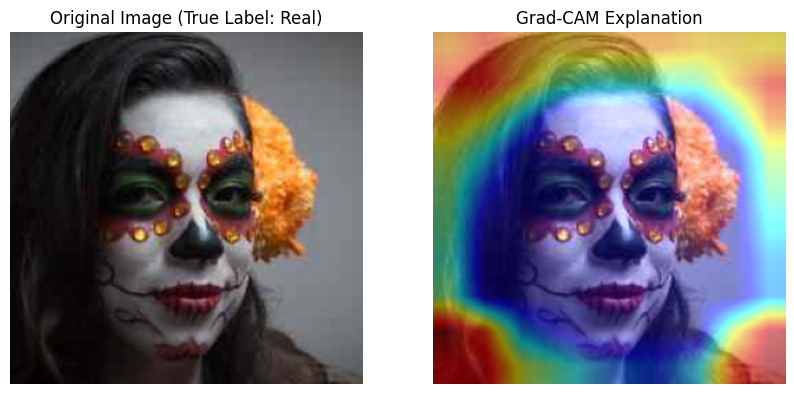

In [19]:
# Target the deepest convolutional layer in Xception
target_layer = model.backbone.conv4 
cam = GradCAM(model, target_layer)

# Grab a single image from our validation loader
model.eval() 
sample_img, sample_label = next(iter(valid_loader))
sample_img = sample_img[0:1].to(device)

# Generate the heatmap
heatmap = cam.generate_heatmap(sample_img)

# --- VISUALIZATION ---
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
disp_img = inv_normalize(sample_img[0].cpu())
disp_img = disp_img.permute(1, 2, 0).numpy()
disp_img = np.clip(disp_img, 0, 1)

heatmap_resized = cv2.resize(heatmap, (299, 299)) # Resized to 299x299 for Xception
heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
heatmap_colored = np.float32(heatmap_colored) / 255
heatmap_colored = heatmap_colored[..., ::-1] 

overlay = heatmap_colored * 0.5 + disp_img
overlay = np.clip(overlay, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(disp_img)
axes[0].set_title(f"Original Image (True Label: {'Fake' if sample_label[0].item() == 1 else 'Real'})")
axes[0].axis('off')

axes[1].imshow(overlay)
axes[1].set_title("Grad-CAM Explanation")
axes[1].axis('off')

plt.show()

Starting Final Evaluation...

--- Final XceptionNet Performance ---
Accuracy:  99.65%
Precision: 99.70%
Recall:    99.60%
F1-Score:  99.65%


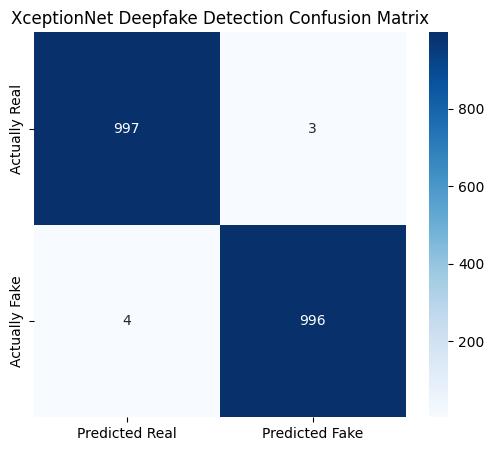

Model weights successfully saved to xception_deepfake_detector.pth!


In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns

print("Starting Final Evaluation...")

model.eval()
all_preds = []
all_labels = []

# We use the valid_loader here to see how well it performs on unseen data
with torch.no_grad():
    for inputs, labels in valid_loader:
        inputs = inputs.to(device)
        labels = labels.to(device).view(-1, 1).float()
        
        outputs = model(inputs)
        probs = torch.sigmoid(outputs)
        preds = (probs > 0.5).float()
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate metrics
acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, zero_division=0)
rec = recall_score(all_labels, all_preds, zero_division=0)
f1 = f1_score(all_labels, all_preds, zero_division=0)

print("\n--- Final XceptionNet Performance ---")
print(f"Accuracy:  {acc * 100:.2f}%")
print(f"Precision: {prec * 100:.2f}%")
print(f"Recall:    {rec * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")

# Draw Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted Real', 'Predicted Fake'], 
            yticklabels=['Actually Real', 'Actually Fake'])
plt.title('XceptionNet Deepfake Detection Confusion Matrix')
plt.show()

# Save the final model weights!
torch.save(model.state_dict(), 'xception_deepfake_detector.pth')
print("Model weights successfully saved to xception_deepfake_detector.pth!")